# Scratch Work for Flow Matching model 

In [1]:
from utils.atoms_to_graphs import AtomsToGraphs
from ase.io import read
import networkx as nx
from matplotlib import pyplot as plt

DEBUG: Entered convert method2!
Data(pos=[40, 3], cell=[1, 3, 3], atomic_numbers=[40], natoms=40, tags=[40], edge_index=[2, 2224], cell_offsets=[2224, 3], fixed=[40])
Graph object: Data(pos=[40, 3], cell=[1, 3, 3], atomic_numbers=[40], natoms=40, tags=[40], edge_index=[2, 2224], cell_offsets=[2224, 3], fixed=[40])
Number of nodes: 40
Number of edges: 2224
Nodes in networkx graph: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39]
Edges in networkx graph: [(0, 2), (0, 11), (0, 5), (0, 6), (0, 1), (0, 9), (0, 15), (0, 3), (0, 7), (0, 17), (0, 14), (0, 16), (0, 18), (0, 25), (0, 24), (0, 10), (0, 4), (0, 8), (0, 13), (0, 12), (0, 19), (0, 20), (0, 22), (0, 26), (0, 23), (0, 21), (1, 9), (1, 7), (1, 3), (1, 2), (1, 10), (1, 16), (1, 8), (1, 4), (1, 15), (1, 12), (1, 17), (1, 26), (1, 19), (1, 25), (1, 11), (1, 5), (1, 6), (1, 14), (1, 13), (1, 18), (1, 20), (1, 23), (1, 24), (1, 21), (1, 22)

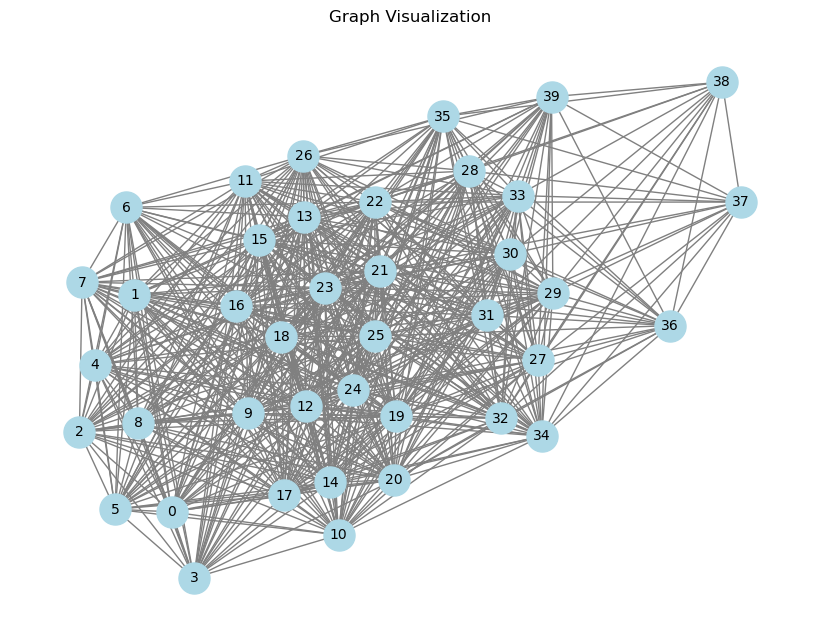

In [3]:
import networkx as nx
import matplotlib.pyplot as plt
from utils.atoms_to_graphs import AtomsToGraphs
from ase.io import read

# Load your structure using ASE
atoms = read('/Users/deanmsweeney/Documents/CFM /CFM-Adsorbate-Placement/flow_matching/data/POSCAR')
#atoms = read('no3.xyz')

# Recreate the converter
converter = AtomsToGraphs()

graph = converter.convert(atoms)  # Assuming this returns a PyTorch Geometric Data object

print(graph)

# Debug: Check the graph structure
print("Graph object:", graph)
print("Number of nodes:", graph.num_nodes)
print("Number of edges:", graph.edge_index.shape[1] if graph.edge_index is not None else 0)

# Convert the graph to a networkx graph
def pytorch_geometric_to_networkx(graph):
    import torch
    import networkx as nx

    # Extract edge indices and node features
    edge_index = graph.edge_index.numpy()  # Convert edge indices to numpy
    node_features = graph.x.numpy() if graph.x is not None else None

    # Create a networkx graph
    G = nx.Graph()

    # Add nodes
    for i in range(graph.num_nodes):
        G.add_node(i, features=node_features[i] if node_features is not None else None)

    # Add edges
    for i in range(edge_index.shape[1]):
        source, target = edge_index[:, i]
        G.add_edge(source, target)

    return G

# Convert the graph to a networkx graph
G = pytorch_geometric_to_networkx(graph)

# Debug: Check the networkx graph
print("Nodes in networkx graph:", G.nodes())
print("Edges in networkx graph:", G.edges())

# Draw the graph
plt.figure(figsize=(8, 6))
pos = nx.spring_layout(G)  # Layout for positioning nodes
nx.draw(G, pos, with_labels=True, node_color='lightblue', edge_color='gray', node_size=500, font_size=10)
plt.title("Graph Visualization")
plt.axis('off')  # Turn off the axis
plt.show()
